In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score, mean_squared_error

In [51]:
# Load dataset
df = pd.read_csv('/content/uber.csv')

# Display first 5 rows
print(df.head())

# Dataset shape
print("\nDataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
print(df.info())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217              1.0  
1         -73.994710         40.750325              1.0  
2         -73.962565         40.772647              1.0  
3         

In [52]:
# Remove unnecessary columns
df = df.drop(['Unnamed: 0', 'key'], axis=1)

# Convert pickup_datetime into datetime format
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'],
    utc=True
)

# Remove missing values
df = df.dropna()

# Extract date and time features
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

# Drop original datetime column
df = df.drop('pickup_datetime', axis=1)

print("Preprocessing Completed!")
print(df.head())
print("\nShape:", df.shape)

Preprocessing Completed!
   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  day  month  year  day_of_week  
0         40.723217              1.0    19    7      5  2015            3  
1         40.750325              1.0    20   17      7  2009            4  
2         40.772647              1.0    21   24      8  2009            0  
3         40.803349              3.0     8   26      6  2009            4  
4         40.761247              5.0    17   28      8  2014            3  

Shape: (160896, 11)


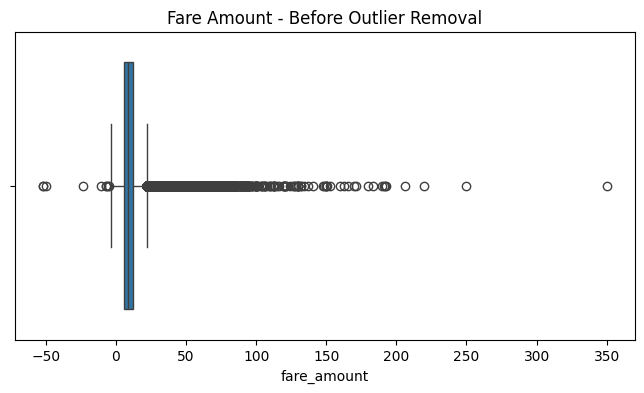

Dataset Shape After Removing Outliers: (143425, 11)


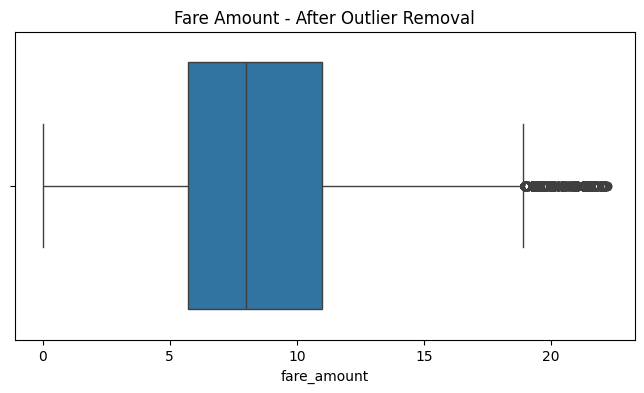

In [53]:
# Visualize fare outliers before removal
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['fare_amount'])
plt.title('Fare Amount - Before Outlier Removal')
plt.show()

# Remove invalid fare values
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= 100)]

# Remove invalid passenger counts
df = df[(df['passenger_count'] >= 1) &
        (df['passenger_count'] <= 6)]

# Keep valid New York City geographical coordinates
df = df[
    (df['pickup_longitude'].between(-74.3, -73.5)) &
    (df['dropoff_longitude'].between(-74.3, -73.5)) &
    (df['pickup_latitude'].between(40.4, 41.0)) &
    (df['dropoff_latitude'].between(40.4, 41.0))
]

# Detect fare outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Remove fare outliers
df = df[
    (df['fare_amount'] >= lower_limit) &
    (df['fare_amount'] <= upper_limit)
]

print("Dataset Shape After Removing Outliers:", df.shape)

# Visualize after removal
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['fare_amount'])
plt.title('Fare Amount - After Outlier Removal')
plt.show()

In [54]:
# Function to calculate distance
def haversine(lat1, lon1, lat2, lon2):

    R = 6371  # Earth radius in km

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

# Calculate distance
df['distance_km'] = haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

print(df[['distance_km', 'fare_amount']].head())

   distance_km  fare_amount
0     1.683323          7.5
1     2.457590          7.7
2     5.036377         12.9
3     1.661683          5.3
4     4.475450         16.0


Correlation with Fare Amount:
fare_amount          1.000000
distance_km          0.799172
year                 0.136725
dropoff_longitude    0.093840
month                0.025791
day_of_week          0.018660
passenger_count      0.012217
day                  0.007621
pickup_longitude     0.003105
hour                -0.013917
pickup_latitude     -0.086051
dropoff_latitude    -0.096485
Name: fare_amount, dtype: float64


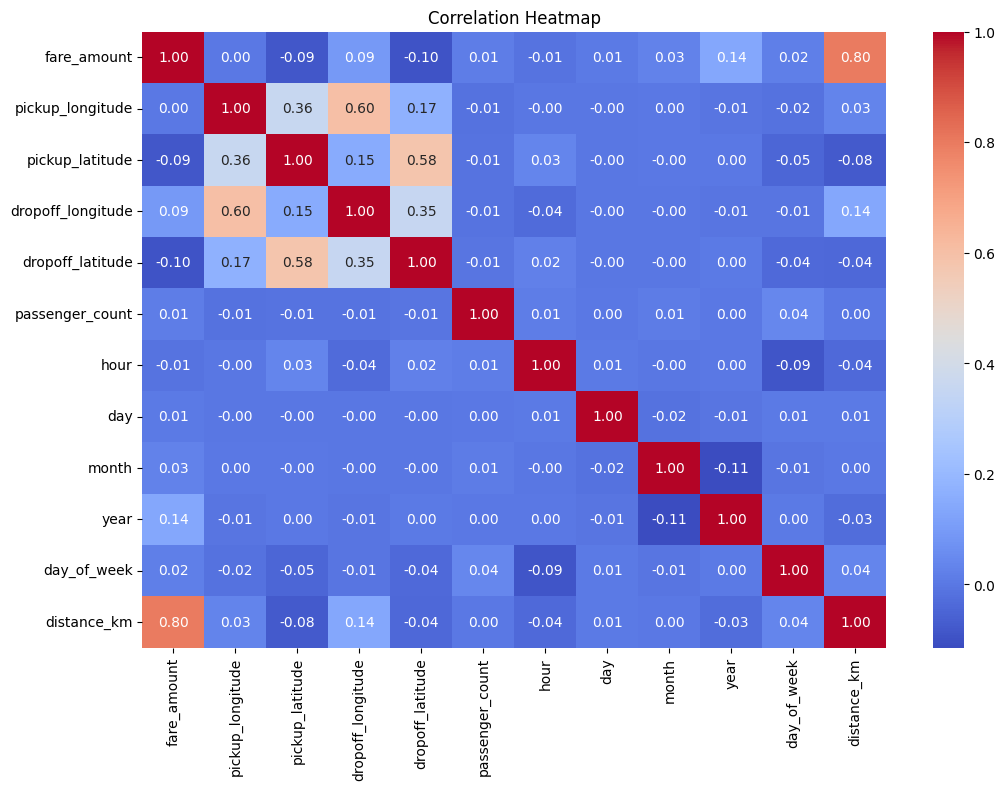

In [55]:
# Calculate correlation matrix
corr = df.corr(numeric_only=True)

# Display correlation with fare
print("Correlation with Fare Amount:")
print(corr['fare_amount'].sort_values(ascending=False))

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [56]:
# Independent variables
X = df.drop('fare_amount', axis=1)

# Dependent variable
y = df['fare_amount']

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

Input Features: (143425, 11)
Target Variable: (143425,)


In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (114740, 11)
Testing Data: (28685, 11)


In [58]:
# Create Linear Regression model
lr = LinearRegression()

# Train model
lr.fit(X_train, y_train)

# Predict fares
y_pred_lr = lr.predict(X_test)

print("Linear Regression Training Completed!")

Linear Regression Training Completed!


In [59]:
# Create Random Forest model
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train model
rf.fit(X_train, y_train)

# Predict fares
y_pred_rf = rf.predict(X_test)

print("Random Forest Regression Training Completed!")

Random Forest Regression Training Completed!


In [60]:
# Calculate R2 score
r2_lr = r2_score(y_test, y_pred_lr)

# Calculate RMSE
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("LINEAR REGRESSION RESULTS")

print("R2 Score:", round(r2_lr, 4))
print("RMSE:", round(rmse_lr, 4))

LINEAR REGRESSION RESULTS
R2 Score: 0.674
RMSE: 2.3607


In [61]:
# Calculate R2 score
r2_rf = r2_score(y_test, y_pred_rf)

# Calculate RMSE
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("RANDOM FOREST RESULTS")

print("R2 Score:", round(r2_rf, 4))
print("RMSE:", round(rmse_rf, 4))

RANDOM FOREST RESULTS
R2 Score: 0.7707
RMSE: 1.9796


In [62]:
# Create comparison table
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [r2_lr, r2_rf],
    'RMSE': [rmse_lr, rmse_rf]
})

print("MODEL PERFORMANCE COMPARISON")
print(comparison)

MODEL PERFORMANCE COMPARISON
               Model  R2 Score      RMSE
0  Linear Regression  0.674006  2.360670
1      Random Forest  0.770750  1.979637


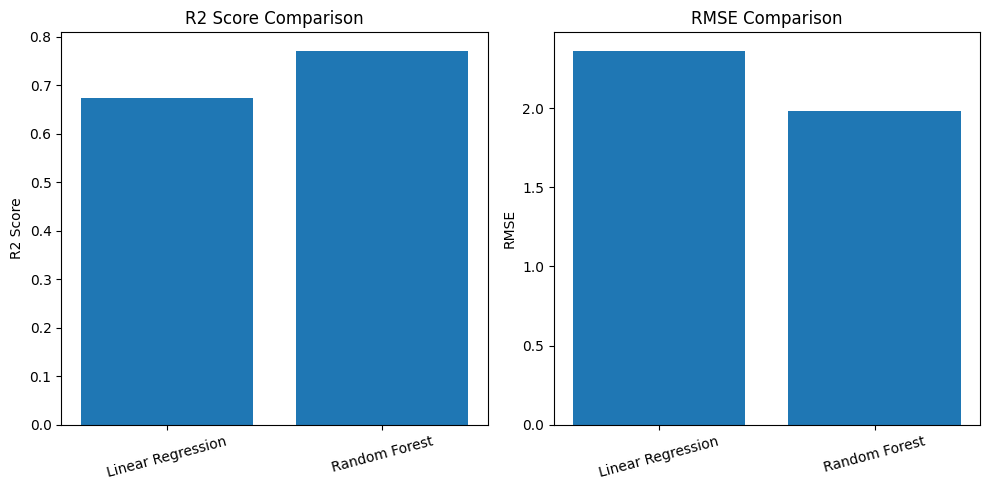

In [63]:
plt.figure(figsize=(10, 5))

# R2 comparison
plt.subplot(1, 2, 1)
plt.bar(
    ['Linear Regression', 'Random Forest'],
    [r2_lr, r2_rf]
)
plt.title('R2 Score Comparison')
plt.ylabel('R2 Score')
plt.xticks(rotation=15)

# RMSE comparison
plt.subplot(1, 2, 2)
plt.bar(
    ['Linear Regression', 'Random Forest'],
    [rmse_lr, rmse_rf]
)
plt.title('RMSE Comparison')
plt.ylabel('RMSE')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [64]:
if r2_rf > r2_lr and rmse_rf < rmse_lr:
    print("Random Forest performs better.")
elif r2_lr > r2_rf and rmse_lr < rmse_rf:
    print("Linear Regression performs better.")
else:
    print("The models have mixed performance.")

print("\nLinear Regression:")
print("R2:", round(r2_lr, 4))
print("RMSE:", round(rmse_lr, 4))

print("\nRandom Forest:")
print("R2:", round(r2_rf, 4))
print("RMSE:", round(rmse_rf, 4))

Random Forest performs better.

Linear Regression:
R2: 0.674
RMSE: 2.3607

Random Forest:
R2: 0.7707
RMSE: 1.9796
